## Import Libraries 
Only libraries useful for this project: Matplolib, Pandas, Plotly


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# 1. Prepare Data

## 1.1 Import Data

Read the CSV file containing the real estate data from Mexico city. 

In [18]:
df1 = pd.read_csv("data/mexico-city-real-estate-1.csv")
df1.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",5500000.0,MXN,5450245.50,289775.66,NaN,54.0,NaN,101851.851852,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/o3zb...
1,sell,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",1512000.0,MXN,1498321.97,79661.96,NaN,80.0,NaN,18900.000000,NaN,NaN,NaN,http://iztapalapa.properati.com.mx/q7t0_venta_...
2,sell,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",926667.0,MXN,918284.00,48822.82,NaN,100.0,NaN,9266.670000,NaN,NaN,NaN,http://tlalpan.properati.com.mx/qbi4_venta_dep...
3,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",6410000.0,MXN,6352013.39,337720.36,NaN,135.0,NaN,47481.481481,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/opeq...
4,sell,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.0,USD,16457437.50,875000.00,0.0,263.0,NaN,3326.996198,NaN,NaN,NaN,http://cancun.properati.com.mx/hg4t_venta_depa...


In [19]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4628 entries, 0 to 4627
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   4628 non-null   str    
 1   property_type               4628 non-null   str    
 2   place_with_parent_names     4628 non-null   str    
 3   lat-lon                     4144 non-null   str    
 4   price                       4538 non-null   float64
 5   currency                    4538 non-null   str    
 6   price_aprox_local_currency  4538 non-null   float64
 7   price_aprox_usd             4538 non-null   float64
 8   surface_total_in_m2         1668 non-null   float64
 9   surface_covered_in_m2       4436 non-null   float64
 10  price_usd_per_m2            1150 non-null   float64
 11  price_per_m2                4249 non-null   float64
 12  floor                       291 non-null    float64
 13  rooms                       136 non-null    

## 1.2 Data Cleaning 


### Drop NaN values from the dataframe `df1`



In [20]:
# show sum of NaN values in each column
df1.isnull().sum()

operation                        0
property_type                    0
place_with_parent_names          0
lat-lon                        484
price                           90
currency                        90
price_aprox_local_currency      90
price_aprox_usd                 90
surface_total_in_m2           2960
surface_covered_in_m2          192
price_usd_per_m2              3478
price_per_m2                   379
floor                         4337
rooms                         4492
expenses                      4623
properati_url                    0
dtype: int64

In [21]:
# find percentage of null values in each column
df1.isnull().mean() * 100

operation                      0.000000
property_type                  0.000000
place_with_parent_names        0.000000
lat-lon                       10.458081
price                          1.944685
currency                       1.944685
price_aprox_local_currency     1.944685
price_aprox_usd                1.944685
surface_total_in_m2           63.958513
surface_covered_in_m2          4.148660
price_usd_per_m2              75.151253
price_per_m2                   8.189283
floor                         93.712187
rooms                         97.061366
expenses                      99.891962
properati_url                  0.000000
dtype: float64

- We do not drop every row or column that contains any null value because this would remove several valuable apartment price predictors, especially location (lat-lon) and usable area (surface_covered_in_m2). Instead, we drop columns with more than 50% null values and columns that create target leakage, we then treat the remaining missing values deliberately.
- In this case, a sensible first pass is to drop:
    - `expenses` — 99.9% missing 
    - `rooms` — 97.1% missing 
    - `floor` — 93.7% missing 
    - `price_usd_per_m2` - 75% missing
    - `surface_total_in_m2` - 64% missing
    - `price_usd_per_m2` and `price_per_m2`— these are calculated from price and area, so they leak information about the target price into the model.
        - A *feature is leakage* if it contains information that would not be available independently at the time you want to predict a listing’s price. Including leakage variables can make validation metrics look unrealistically strong while hurting real-world generalization
    - `price_aprox_usd`, `price_aprox_local_currency`, and possibly `currency` — if price is the target, these are alternate representations or direct transformations of the target, so they should not be predictors - i.e. we have to choose one price target to focus on and remove the rest:
        - all price columns () have same NaN value percentage at 1.944685, therefore they are similar. Since we will be dealing with USD, we'll keep `price_aprox_usd`
    - `properati_url` — this is just a listing identifier/URL, i.e not a stable property characteristic. Same with `operation`
- We keep `lat-lon` and `surface_covered_in_m2`; both contain important signals for apartment price prediction since geographic location and size of apartment are good predictors of apartment prices. Also, their NaN value percentages are low enough to be acceptable since we can later drop them without affecting the predicting power of the source data.

In [22]:
# drop nan columns and leakage columns

columns_to_drop = [
    'expenses',
    'rooms',
    'floor',
    'price_usd_per_m2',
    'price_per_m2',
    'price_aprox_local_currency',
    'price',
    'currency',
    'surface_total_in_m2',
    'properati_url',
    'operation' 
]

# Drop these columns completely
df1 = df1.drop(columns=columns_to_drop)

df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
1,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",79661.96,80.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0


In [23]:
# investigate the number of remaining NaN values
df1.isnull().sum()

property_type                0
place_with_parent_names      0
lat-lon                    484
price_aprox_usd             90
surface_covered_in_m2      192
dtype: int64

### Filter Apartment Type only

- Since we don't want to arbitrarily remove NaN values, we can further clean the data by focussing on the data we want and then we can later come back to remove any NaN values.
    - We start with focusing on the `property_tupe = apartment` since that is the type of property we will be predicting prices for

In [24]:
mask_aprt_type = df1["property_type"] =="apartment"
df1 = df1[mask_aprt_type]


In [25]:
df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,apartment,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


In [26]:
# Double check there is only one property type = apartment. Then drop the property_type column
df1["property_type"].value_counts()


property_type
apartment    3123
Name: count, dtype: int64

In [27]:
#drop the property_type column
df1.drop(columns=["property_type"], inplace = True)

df1.head()

,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


### Separate `lat-lon` column into two columns `lat` and `lon`

- Since we need precise latitude and longitude, we separate the lat and lon column from `lat-lon` 
- We also ensure that the two columns are of `float` data type

In [28]:
# Seperate and drop "lat-lon" column
df1[["lat", "lon"]] = df1["lat-lon"].str.split(",", expand = True).astype(float)
df1.drop(columns = ["lat-lon"], inplace = True)

In [29]:
df1.head()

,place_with_parent_names,price_aprox_usd,surface_covered_in_m2,lat,lon
0,|Miguel Hidalgo|Distrito Federal|México|,289775.66,54.0,23.634501,-102.552788
2,|Tlalpan|Distrito Federal|México|,48822.82,100.0,19.279771,-99.234597
3,|Miguel Hidalgo|Distrito Federal|México|,337720.36,135.0,23.634501,-102.552788
4,|Benito Juárez|Quintana Roo|México|,875000.00,263.0,21.190264,-86.819838
5,|Miguel Hidalgo|Distrito Federal|México|,232663.51,87.0,19.432657,-99.177444


### Create Borough column from place_with_parent_names

- We need names of individual boroughs to be able to distinguish the data by borough location rather than the less useful `place_with_parent_names` column
    - the borough name are in the first index
- Ensure to drop the column afterwards

In [30]:
# Create "borough" feature from "place_with_parent_names"
df1["borough"] = df1["place_with_parent_names"].str.split("|", expand = True)[1]
    # [1] grabs the second column of the newly split data (the item right after the first vertical bar) since in Pythn counting starts at 0
df1.drop(columns = ["place_with_parent_names"], inplace = True)

In [31]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
Index: 3123 entries, 0 to 4627
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        3113 non-null   float64
 1   surface_covered_in_m2  2974 non-null   float64
 2   lat                    2801 non-null   float64
 3   lon                    2801 non-null   float64
 4   borough                3123 non-null   str    
dtypes: float64(4), str(1)
memory usage: 146.4 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,borough
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo
2,48822.82,100.0,19.279771,-99.234597,Tlalpan
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo


In [75]:
# Check boroughs in the `borough` column

df1['borough'].is_unique()

TypeError: 'bool' object is not callable

- The dataset should only feature boroughs in Mexico City, and yet it features region outside CDMX. 
    - We have to drop those rows to avoid data contamination.

In [32]:
# Check for remaining sum of NaN values

df1.isnull().sum() 

price_aprox_usd           10
surface_covered_in_m2    149
lat                      322
lon                      322
borough                    0
dtype: int64

### Remove outliers

- I should have properly done this sooner but, better late than never!
- Real estate data is heavily right-skewed (a few massive penthouses exist, but negative space is impossible), which means symmetric trimming rules like 3-Sigma or fixed 10% cuts will distort data and hurt the machine learning model. Also, in real-world datasets, extreme outliers are often data entry errors. 

- Remember we still have NaN values. To further reduce the values lets remove the outliers by trimming outliers in the `surface_covered_in_m2` and `price_aprox_usd` columns.
    - This is important as it helps in reducing the number of false positives/negatives due to imbalanced data. e.g. Apartments that are larger or smaller than usual are typically outliers.
    - Outliers heavily skew both the mean and the standard deviation, meaning any model that includes outliers may be biased 

#### Remove Area Outliers

- According to my Market Research, Apartments in Mexico City generally range in size from 30 m² to 125 m² for standard units, with a typical city-wide average of 60 - 85 m².
    - Studios and Compact Lofts: 30 - 45 m² 
    - 1-Bedroom Apartments: 45 - 75 m² 
    - 2- to 3-Bedroom Apartments: 75 - 125 m²
    - Luxury Residences and Penthouses: 130 - 300+ m² 

Statistics for `surface_covered_in_m2`:

count     2974.000000
mean       131.362475
std        618.345607
min          0.000000
25%         62.000000
50%         80.000000
75%        121.000000
max      31840.000000
Name: surface_covered_in_m2, dtype: float64



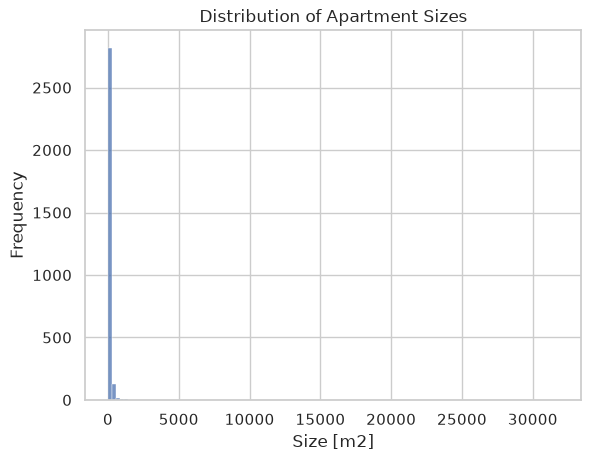

In [33]:
# Show general statistics for "surface_covered_in_m2" 
print("Statistics for `surface_covered_in_m2`:\n")
print(df1["surface_covered_in_m2"].describe())
print()

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='surface_covered_in_m2', 
             kde=False
)
plt.xlabel("Size [m2]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Sizes")
plt.show()


- **Key Details:**
    - The min size is zero, hence we have to remove apartments where size is equal to zero - its unrealistic
    - Considering typical smallest apartments in Mexico City are no less than 30, we will let the *min size in our datset be 20 to avoid cutting off some possible smaller apartment*, albeit rare. 
    - More than 75% of apartments are below 130 m<sup>2</sup> which is expected by the real-world data, hence, the max size of 31,840 is extremely unlikely considering most big apartments don't go past 300. To *avoid cutting off most possible luxury apartments, we will let the max size in our dataset be 500* to be safe.

count    2815.000000
mean      102.662522
std        61.486974
min        23.000000
25%        63.000000
50%        80.000000
75%       119.000000
max       350.000000
Name: surface_covered_in_m2, dtype: float64


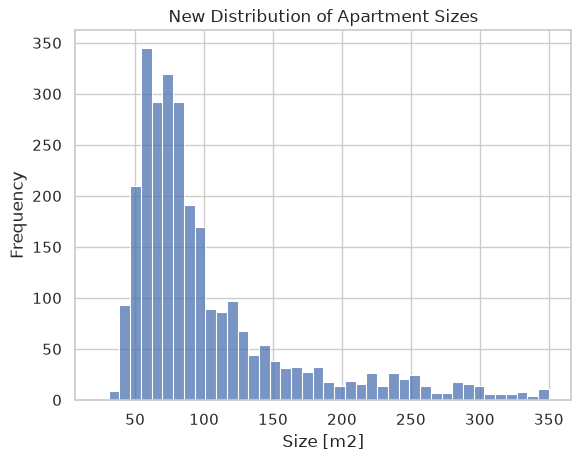

In [34]:
# Remove outliers in 'surface_covered_in_m2'
mask_size_20 = df1["surface_covered_in_m2"] >= 20
mask_size_500 = df1["surface_covered_in_m2"] <= 350
df1 = df1[mask_size_20 & mask_size_500]
print(df1["surface_covered_in_m2"].describe())  # shows reduced to 2865 from 2974, 109 deleted rows

# New-Histogram for size distribution

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='surface_covered_in_m2', 
             kde=False
)
plt.xlabel("Size [m2]")
plt.ylabel("Frequency")
plt.title("New Distribution of Apartment Sizes")
plt.show()

- **Results**
    - Thise new histogram shows a more realistic CDMX apartment size distribution. Even though its still skewed, this is an expected view of real data as the luxury apartments are at a realistic size, and so are the cheapest ones.

- **Way Forward**
    - Create a Log Transformation column 
        -  a log transformation is used to compress large numbers and spread out small numbers. It helps turn highly skewed, exponential-looking data into a symmetric, normal distribution so it is easier to model, especially when using Linear Regression or Neural Networks

        - log_surface_covered_in_m2 = log(1+surface_covered_in_m2)

In [35]:
# Creating a log transformation column
df1['log_surface_covered_in_m2'] = np.log(df1['surface_covered_in_m2'])
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez,5.572154
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908


#### Remove Price Outliers

Statistics for `price_aprox_usd`:

count       2807
mean      194637
std       301775
min         7824
25%        52523
50%       104344
75%       219100
max      8429837
Name: price_aprox_usd, dtype: int64


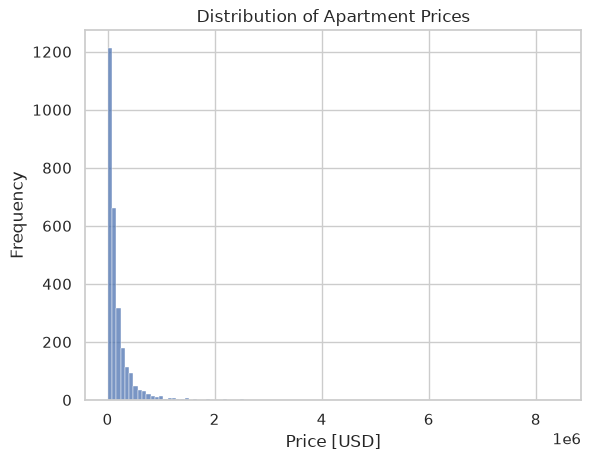

In [36]:
# Show general statistics for "price_aprox_usd",rounded to 0 decimal places and converted to integers
print("Statistics for `price_aprox_usd`:\n")
print(df1["price_aprox_usd"].describe().round(0).astype(int))

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='price_aprox_usd', 
             kde=False
)
plt.xlabel("Price [USD]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Prices")
plt.show()

- **Key Details:**
    - The median price is $105,742, and more than 75% of all apartments in the city cost less than $229,241. 
    - The mean is $214,105 which is more than double the median, meaning the data is heavily skewed by a few incredibly expensive properties.
    - Hence, the $8,429,837 max price is an extreme case which has to be removed alongside other high outliers. This also goes for low outliers like the $7,824 min price which is exceptionally low for an apartment in CDMX and is most likely a data entry error or a parking spot/storage unit listed as an apartment.
    - To remove outliers, we can target the extreme outliers 
        - *Removing high outliers*: the data completely disappears after about $1.5M, leaving a big empty void all the way out to $8.4M. It is reasonable that a cutoff at $1M preserves real luxury listings while deleting the extreme ourtliers. 
        - *Removing low outliers*: in CDMX, buying any apartment at less than $30,000 is unrealistic. 
    

Count of new price stats: count      2568
mean     169052
std      161009
min       30031
25%       57913
50%      107397
75%      212060
max      893500
Name: price_aprox_usd, dtype: int64


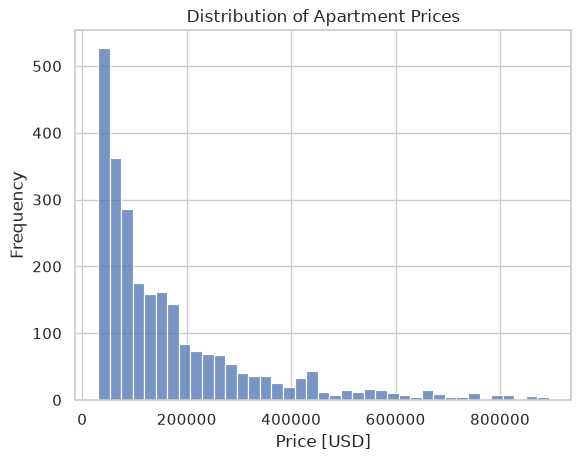

In [46]:
# Remove outliers in 'price_aprox_usd'
mask_lowp= df1['price_aprox_usd'] >= 30000
mask_highp = df1['price_aprox_usd'] <=900000

#Remove outliers
df1 = df1[mask_lowp & mask_highp] 

print(f"Count of new price stats: {df1['price_aprox_usd'].describe().round(0).astype(int)}")  

# Histogram using seaborn for Price Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='price_aprox_usd', 
             kde=False
)
plt.xlabel("Price [USD]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Prices")
plt.show()

- **Results**
    - This new histogram shows a more realistic CDMX apartment price distribution. Even though its still skewed, this is an expected real-world skeweness

- **Way Forward**
    - Creating a Log Transformation column for price like we did with size
     

In [47]:
# Creating a log transformation column for 'price_aprox_usd'
df1['log_price_aprox_used'] = np.log(df1['price_aprox_usd'])
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2,log_price_aprox_used
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984,12.576862
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170,10.795953
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275,12.729973
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez,5.572154,13.681979
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908,12.357349



## Drop Remaining NaN values

- To drop the last NaN values, which are all in the `lat` and `lon` columns, we use the Groupby Imputation method. 

In [50]:
df1.info()

<class 'pandas.DataFrame'>
Index: 2568 entries, 0 to 4627
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2568 non-null   float64
 1   surface_covered_in_m2      2568 non-null   float64
 2   lat                        2355 non-null   float64
 3   lon                        2355 non-null   float64
 4   borough                    2568 non-null   str    
 5   log_surface_covered_in_m2  2568 non-null   float64
 6   log_price_aprox_used       2568 non-null   float64
dtypes: float64(6), str(1)
memory usage: 160.5 KB



    - Since we have a complete `borough` column for all 2,568 rows, we can fill the missing coordinates with the average latitude and longitude of the other apartments located in that exact same `borough`.

In [ ]:
# Filling the missing lat/lon with the average of their specific borough
df1['lat'] = df1['lat'].fillna(df1.groupby('borough')['lat'].transform('mean'))
df1['lon'] = df1['lon'].fillna(df1.groupby('borough')['lon'].transform('mean'))

# confirming `0` NaN values remain
print(df1.info())


<class 'pandas.DataFrame'>
Index: 2568 entries, 0 to 4627
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2568 non-null   float64
 1   surface_covered_in_m2      2568 non-null   float64
 2   lat                        2568 non-null   float64
 3   lon                        2568 non-null   float64
 4   borough                    2568 non-null   str    
 5   log_surface_covered_in_m2  2568 non-null   float64
 6   log_price_aprox_used       2568 non-null   float64
dtypes: float64(6), str(1)
memory usage: 160.5 KB
None


# 2. Explore Data

In this section, I explore the data via visualization to learn more about the CDMX data, regional differences, price distribution, etc. 


In [52]:
# Review current dataframe, df1
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2,log_price_aprox_used
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984,12.576862
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170,10.795953
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275,12.729973
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez,5.572154,13.681979
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908,12.357349


## 2.1 Location Distribution

In [55]:
fig = px.scatter_map(
    df1,
    lat="lat",                     
    lon="lon",                  
    center={"lat": 19.43, "lon": -99.13}, # 
    width=800,
    height=500,
    hover_data=["price_aprox_usd"],
    zoom=10,                         # controls how close the map is zoomed in
    map_style="open-street-map"
)

fig.show()


## 2.2 Apartment Price Distribution by Borough

- It may important to show the average price of apartments in each Borough in Mexico City
- It helps show where the most expensive apartments are located and where the cheapest are. It gives an overview of how region affects prices.
- Noting where most apartments are located:

In [61]:
#Creating a series `mean_price_by_borough` using groupby to show the mean home price in each borough in CDMX
mean_price_by_borough = df1.groupby('borough')['price_aprox_usd'].mean().sort_values(ascending = True)
mean_price_by_borough.head()

borough
Tabasco       39514.860000
Cozumel       45000.000000
Tláhuac       51681.556923
Iztapalapa    54761.365904
Iztacalco     58328.687215
Name: price_aprox_usd, dtype: float64

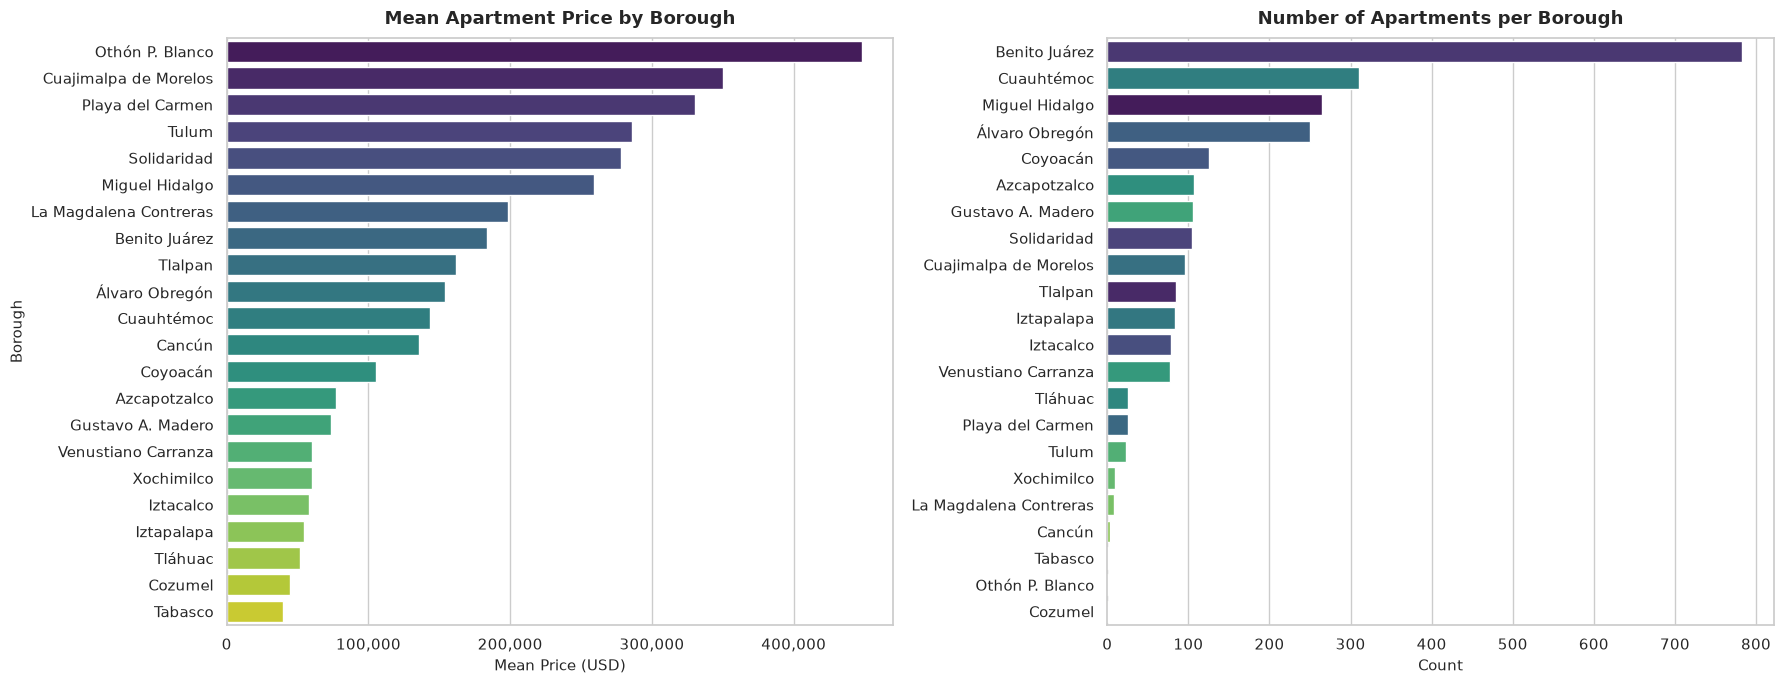

In [71]:
## Bar charts showing the mean price and the number of apartments by borough in CDMX

# Preparing data for the first bar chart (Mean Apartment Price per Borough)
df_price = mean_price_by_borough.reset_index()
df_price.columns = ['borough', 'mean_price']
df_price = df_price.sort_values(by='mean_price', ascending=False)

# Preparing data for second bar chart (Number of Apartments per Borough)
count_order = df1['borough'].value_counts().index



# Creating Bar Charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# --- Bar Chart 1: Mean Apartment Price ---
sns.barplot(
    data=df_price, 
    x='mean_price', 
    y='borough', 
    hue='borough',    
    legend=False,     
    palette='viridis',
    ax=axes[0]        # Assign to the first subplot axis
)
axes[0].set_title('Mean Apartment Price by Borough', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Mean Price (USD)', fontsize=11)
axes[0].set_ylabel('Borough', fontsize=11)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# --- Bar Chart 2: Number of Apartments ---
sns.countplot(
    data=df1, 
    y='borough', 
    hue='borough',                              
    order=count_order,  
    palette='viridis',
    legend=False,                                
    ax=axes[1]        # Assign to the second subplot axis
)
axes[1].set_title('Number of Apartments per Borough', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Count', fontsize=11)
axes[1].set_ylabel('')  # Remove y-label to avoid cluttering the middle space

# display
plt.tight_layout()
plt.show()


- **Notable Details**
    - *Most expensive* listings are overwhelmingly concentrated in Othón P. Blanco (averaging ~$450,000 USD) and Cuajimalpa de Morelos ( ~$350,000 USD). Conversely,  have the lowest average prices, sitting well below $50,000 USD.
    - *Dominance* Benito Juárez has the biggest concentration of apartments with nearly 800 listings, followed by Cuauhtémoc (~310) and Miguel Hidalgo (~260).



    
    - The "High-Value, Low-Sample" Risk: The areas with the highest average prices—specifically Othón P. Blanco, Playa del Carmen, and Tulum—show up at the absolute bottom of the count chart with nearly 0 listings. Because these averages are calculated from just a few isolated luxury properties, they are highly volatile and could easily skew a predictive machine learning model.

## 2.3. Correlation of Price to other columns
- Which of the columns are good contributors to the price?
- We use a heatmap for this.

In [ ]:
# Calculate Pearson correlation coefficient
correlation = df1['surface_covered_in_m2'].corr(df1['price_aprox_usd'])
print(f"Correlation between size and price: {correlation:.2f}")


In [ ]:
print(df1["surface_covered_in_m2"].sort_values(ascending=False))